In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
train_df = pd.read_csv("../data/raw/train.csv")
test_df = pd.read_csv("../data/raw/test.csv")

In [3]:
train_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
train_df.shape

(891, 12)

In [5]:
test_df.shape

(418, 11)

In [6]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [7]:
train_df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [8]:
train_df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [9]:
train_df["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [10]:
train_df["Survived"].value_counts(normalize=True) * 100

Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

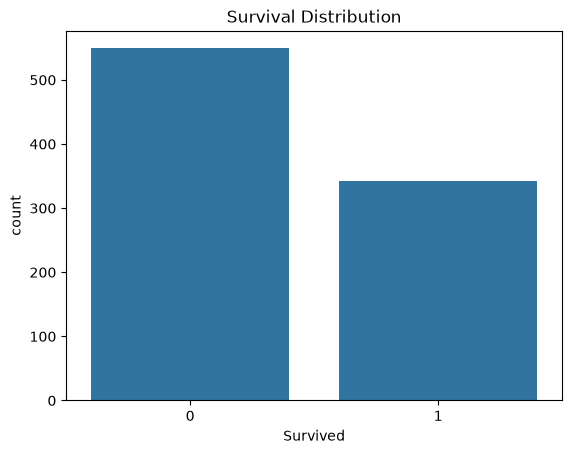

In [11]:
sns.countplot(data=train_df, x="Survived")
plt.title("Survival Distribution")
plt.show()

In [12]:
train_df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [13]:
train_df["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [14]:
train_df["Survived"].value_counts(normalize=True) * 100

Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

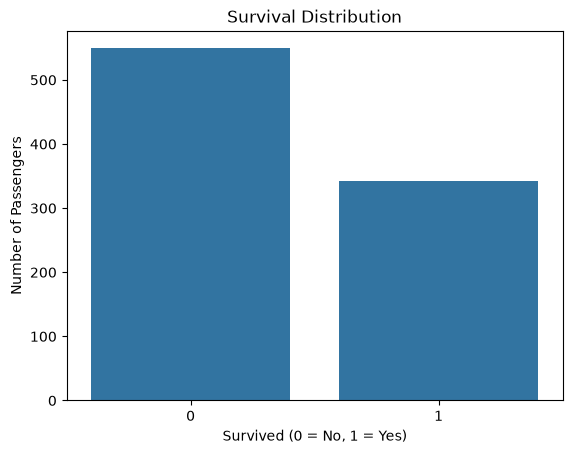

In [15]:
sns.countplot(data=train_df, x="Survived")

plt.title("Survival Distribution")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

## Survival Analysis by Sex

In this section, we investigate whether passenger sex
was associated with survival.

In [16]:
train_df.groupby("Sex")["Survived"].mean() * 100

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

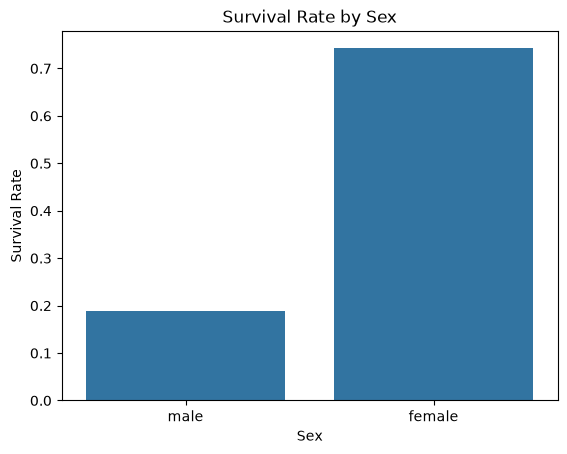

In [17]:
sns.barplot(
    data=train_df,
    x="Sex",
    y="Survived",
    errorbar=None
)

plt.title("Survival Rate by Sex")
plt.xlabel("Sex")
plt.ylabel("Survival Rate")
plt.show()

### Finding: Survival by Sex

The exploratory analysis revealed a significant difference
in survival rates between male and female passengers.

- Female survival rate: 74.20%
- Male survival rate: 18.89%

Female passengers had a substantially higher survival rate
than male passengers.

This suggests that Sex could be an important predictive
feature for our machine learning model.

In [18]:
train_df.groupby("Pclass")["Survived"].mean() * 100

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

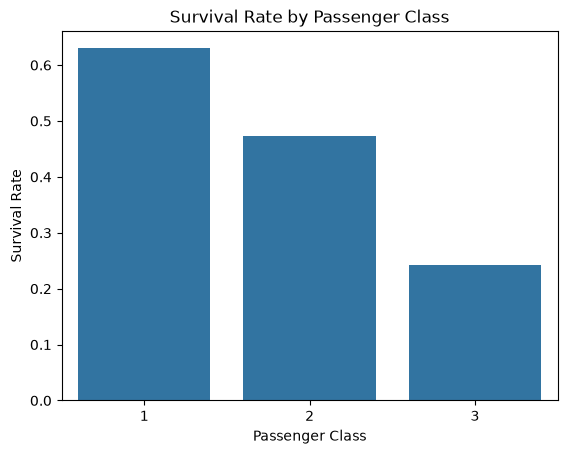

In [19]:
sns.barplot(
    data=train_df,
    x="Pclass",
    y="Survived",
    errorbar=None
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.show()

### Finding: Survival by Passenger Class

The analysis revealed a relationship between passenger class and survival.

- First-class survival rate: 62.96%
- Second-class survival rate: 47.28%
- Third-class survival rate: 24.24%

First-class passengers had the highest survival rate, while third-class passengers had the lowest.

The difference between first-class and third-class survival rates was approximately 38.72 percentage points.

**Conclusion:** Passenger class (`Pclass`) appears to be a useful candidate feature for predicting survival.

In [20]:
train_df.groupby(["Sex", "Pclass"])["Survived"].mean() * 100

Sex     Pclass
female  1         96.808511
        2         92.105263
        3         50.000000
male    1         36.885246
        2         15.740741
        3         13.544669
Name: Survived, dtype: float64

In [21]:
train_df.groupby("Sex")["Survived"].mean() * 100

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

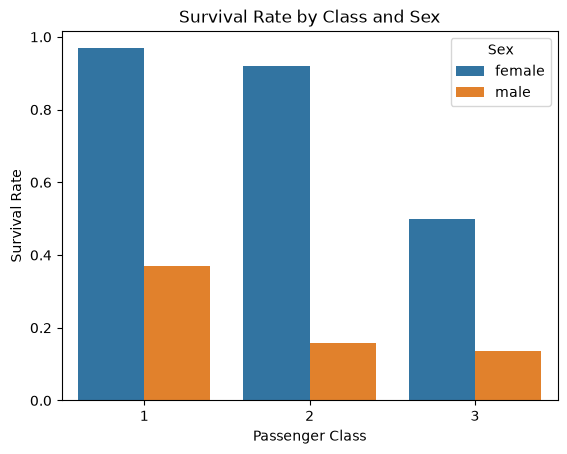

In [22]:
sns.barplot(
    data=train_df,
    x="Pclass",
    y="Survived",
    hue="Sex",
    errorbar=None
)

plt.title("Survival Rate by Class and Sex")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.show()

### Finding: Survival by Sex and Passenger Class

The analysis revealed that both sex and passenger class
were associated with survival.

- First-class females had the highest survival rate (96.81%).
- Third-class males had the lowest survival rate (13.54%).
- Female passengers had higher survival rates than male
  passengers across all three classes.
- Survival rates generally decreased as passenger class
  changed from first to third.

These findings suggest that Sex and Pclass are promising
features for our machine learning model.

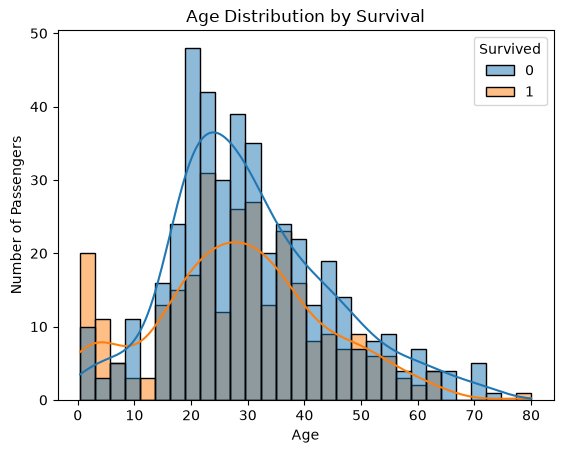

In [23]:
sns.histplot(
    data=train_df,
    x="Age",
    hue="Survived",
    bins=30,
    kde=True
)

plt.title("Age Distribution by Survival")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.show()

In [24]:
train_df.groupby("Survived")["Age"].mean()

Survived
0    30.626179
1    28.343690
Name: Age, dtype: float64

In [25]:
children = train_df[train_df["Age"] < 16]

children["Survived"].value_counts(normalize=True) * 100

Survived
1    59.036145
0    40.963855
Name: proportion, dtype: float64

In [26]:
known_age = train_df.dropna(subset=["Age"]).copy()

known_age["AgeGroup"] = known_age["Age"].apply(
    lambda age: "Child" if age < 16 else "Adult"
)

known_age.groupby("AgeGroup")["Survived"].mean() * 100

AgeGroup
Adult    38.193344
Child    59.036145
Name: Survived, dtype: float64

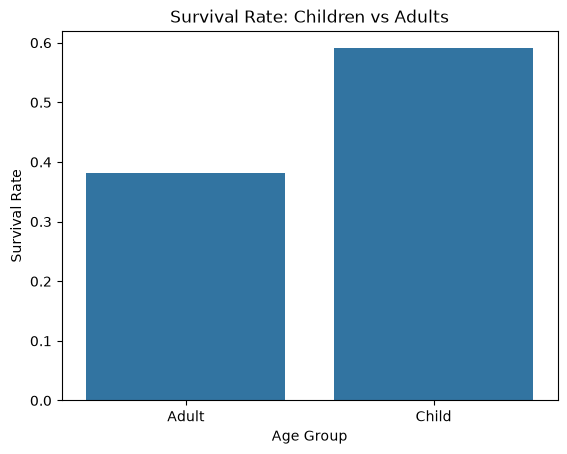

In [27]:
sns.barplot(
    data=known_age,
    x="AgeGroup",
    y="Survived",
    errorbar=None
)

plt.title("Survival Rate: Children vs Adults")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate")
plt.show()

### Finding: Age and Survival

The analysis revealed several patterns:

- Average age of survivors: 28.34 years.
- Average age of non-survivors: 30.63 years.
- Approximately 59.04% of children under 16 survived.
- Survival outcomes varied across age groups.

Age may be a useful feature for predicting survival.

However, 177 passengers have missing age values,
so missing data must be handled during preprocessing.

These observations are based on passengers with
recorded ages.

In [29]:
known_age = train_df.dropna(subset=["Age"]).copy()

known_age["AgeGroup"] = pd.cut(
    known_age["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teen", "Young Adult", "Adult", "Senior"]
)

known_age.groupby(
    ["AgeGroup", "Pclass"],
    observed=True
)["Survived"].agg(["count", "mean"])

count      mean
AgeGroup    Pclass                 
Child       1           4  0.750000
            2          17  1.000000
            3          48  0.416667
Teen        1          12  0.916667
            2          12  0.500000
            3          46  0.282609
Young Adult 1          66  0.757576
            2          94  0.436170
            3         198  0.232323
Adult       1          90  0.611111
            2          47  0.382979
            3          58  0.086207
Senior      1          14  0.214286
            2           3  0.333333
            3           5  0.200000

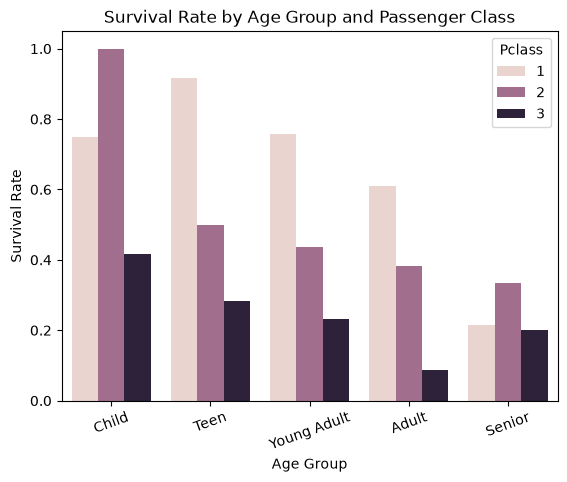

In [30]:
sns.barplot(
    data=known_age,
    x="AgeGroup",
    y="Survived",
    hue="Pclass",
    errorbar=None
)

plt.title("Survival Rate by Age Group and Passenger Class")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate")
plt.xticks(rotation=20)
plt.show()

### Finding: Age Group and Passenger Class

The analysis examined survival rates across five age
groups and three passenger classes.

Key observations:

- Young adults in first class had a survival rate of 75.76%,
  compared with 23.23% in third class.
- All 17 second-class children in the dataset survived.
- Third-class adults aged over 35 and up to 60 had a
  particularly low survival rate of 8.62%.
- Some groups, particularly seniors, contained very few
  passengers, making their survival rates less reliable.

Conclusion:

Age and passenger class appear to be associated with
survival outcomes. These features may help our predictive
model, but further evaluation is necessary.

This analysis excludes passengers with missing ages.